# Project 1: How the Jones Polynomial Relates to Knot Topology

**Question.** The Jones polynomial is a *quantum* invariant: it comes from physics and representation theory, not from
the geometry of the knot. How much does it know about classical and geometric properties such as the
crossing number, the determinant, and hyperbolic volume?

**Data.** All 2,977 prime knots with 3 to 12 crossings from [KnotInfo](https://knotinfo.math.indiana.edu),
the standard database of knot invariants, loaded with the `knotml` package in this repository.

**What this notebook does.**
1. Checks two known theorems against the data, as a test that the data and code are right.
2. Measures how well simple invariants predict hyperbolic volume.
3. Tests a published conjecture about volume and the determinant on every alternating knot in the data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ALT, NONALT = "#257de0", "#f47230"   # blue = alternating, orange = non-alternating
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

from knotml import load_knots, evaluate_jones

df = load_knots()          # builds data/knots.csv from KnotInfo on first run
print(len(df), "knots;", df["alternating"].sum(), "alternating,", (~df["alternating"]).sum(), "non-alternating;",
      df["hyperbolic"].sum(), "hyperbolic")
df[["name", "crossing_number", "alternating", "determinant", "signature", "volume", "jones_polynomial"]].head()

2977 knots; 1851 alternating, 1126 non-alternating; 2970 hyperbolic


,name,crossing_number,alternating,determinant,signature,volume,jones_polynomial
0,3_1,3,True,3,-2,0.000000,t+ t^3-t^4
1,4_1,4,True,5,0,2.029883,t^(-2)-t^(-1)+ 1-t+ t^2
2,5_1,5,True,5,-4,0.000000,t^2+ t^4-t^5+ t^6-t^7
3,5_2,5,True,7,-2,2.828122,t-t^2+ 2*t^3-t^4+ t^5-t^6
4,6_1,6,True,9,0,3.163963,t^(-2)-t^(-1)+ 2-2*t+ t^2-t^3+ t^4


## 1. Sanity check: the determinant is the Jones polynomial at t = −1

A classical fact: for every knot, det(K) = |V(−1)|, where V is the Jones polynomial. If our parsing of the
Jones polynomial were wrong, this would fail. KnotInfo stores V as `[min_degree, max_degree, coefficients...]`,
so V(−1) = Σ cᵢ · (−1)^(min_degree + i).

In [2]:
df["abs_V_at_minus1"] = [abs(evaluate_jones(v, lo, -1)) for v, lo in zip(df["coeffs"], df["jones_min_degree"])]
matches = np.isclose(df["abs_V_at_minus1"], df["determinant"])
print(f"det(K) = |V(-1)| holds for {matches.sum()} of {len(df)} knots")

det(K) = |V(-1)| holds for 2977 of 2977 knots


## 2. The span of the Jones polynomial detects alternating knots

The **span** of V is max degree − min degree. The Kauffman–Murasugi–Thistlethwaite theorem (1987) says:
for a reduced alternating diagram, span V = crossing number; for a non-alternating prime knot, span V < crossing number.
This theorem settled a century-old Tait conjecture. Let's see it in the data.

Alternating:     span = crossing number for 1851 of 1851
Non-alternating: span < crossing number for 1126 of 1126


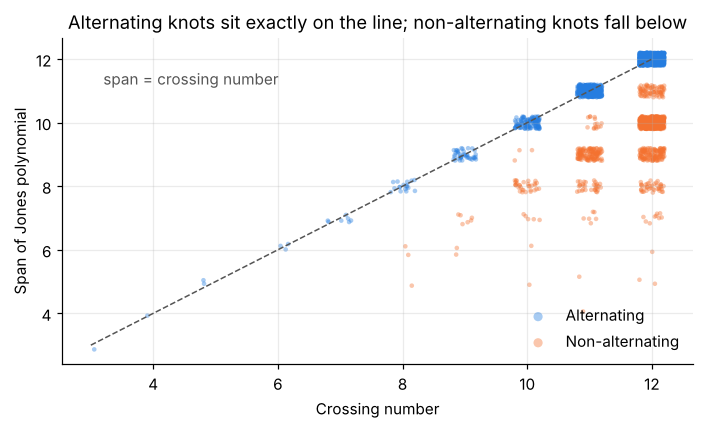

In [3]:
df["span"] = df["jones_max_degree"] - df["jones_min_degree"]
alt, non = df[df["alternating"]], df[~df["alternating"]]
print(f"Alternating:     span = crossing number for {(alt.span == alt.crossing_number).sum()} of {len(alt)}")
print(f"Non-alternating: span < crossing number for {(non.span < non.crossing_number).sum()} of {len(non)}")

fig, ax = plt.subplots(figsize=(6.5, 4))
# Both axes are whole numbers, so many knots share a point. Small random "jitter" spreads them out to show density.
rng = np.random.default_rng(0)
for sub, col, lab in [(alt, ALT, "Alternating"), (non, NONALT, "Non-alternating")]:
    jx, jy = rng.uniform(-0.2, 0.2, len(sub)), rng.uniform(-0.2, 0.2, len(sub))
    ax.scatter(sub.crossing_number + jx, sub.span + jy, s=9, alpha=0.4,
               color=col, label=lab, edgecolor="none")
ax.plot([3, 12], [3, 12], color="#555", lw=1, ls="--")
ax.text(3.2, 11.2, "span = crossing number", color="#555")
ax.set(xlabel="Crossing number", ylabel="Span of Jones polynomial",
       title="Alternating knots sit exactly on the line; non-alternating knots fall below")
ax.legend(frameon=False, loc="lower right", markerscale=2)
plt.tight_layout(); plt.savefig("figures/p1_span_vs_crossing.png", dpi=150); plt.show()

## 3. Which invariant predicts hyperbolic volume?

All but 7 of these knots are **hyperbolic**: their complement in 3-space has a unique hyperbolic geometry,
and its volume is a topological invariant. Volume is geometric, so it is not obvious that a combinatorial or
quantum invariant should predict it. We compare two candidates: crossing number and log(determinant).

Correlation of volume with crossing number:   r = 0.47
Correlation of volume with log(determinant):  r = 0.84  (all hyperbolic knots)
   alternating knots only:                    r = 0.97  (n = 1846)
   non-alternating knots only:                r = 0.79  (n = 1124)


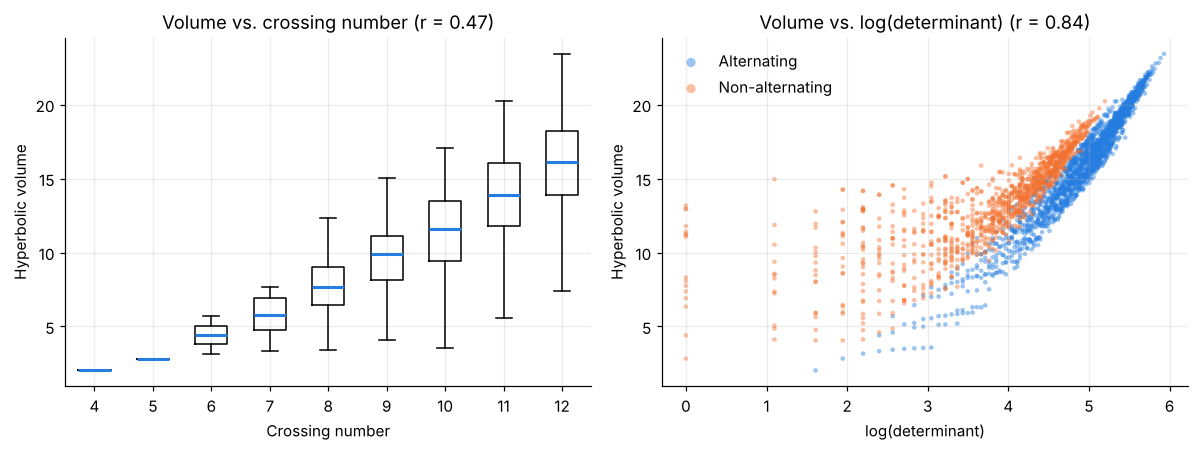

In [4]:
h = df[df["hyperbolic"]].copy()
h["log_det"] = np.log(h["determinant"].clip(lower=1))
r_cross = np.corrcoef(h.volume, h.crossing_number)[0, 1]
r_det = np.corrcoef(h.volume, h.log_det)[0, 1]
ha, hn = h[h.alternating], h[~h.alternating]
print(f"Correlation of volume with crossing number:   r = {r_cross:.2f}")
print(f"Correlation of volume with log(determinant):  r = {r_det:.2f}  (all hyperbolic knots)")
print(f"   alternating knots only:                    r = {np.corrcoef(ha.volume, ha.log_det)[0,1]:.2f}  (n = {len(ha)})")
print(f"   non-alternating knots only:                r = {np.corrcoef(hn.volume, hn.log_det)[0,1]:.2f}  (n = {len(hn)})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
groups = [h[h.crossing_number == n].volume for n in range(4, 13)]
ax.boxplot(groups, positions=range(4, 13), widths=0.55, showfliers=False,
           medianprops=dict(color=ALT, lw=2))
ax.set(xlabel="Crossing number", ylabel="Hyperbolic volume", title=f"Volume vs. crossing number (r = {r_cross:.2f})")

ax = axes[1]
for sub, col, lab in [(ha, ALT, "Alternating"), (hn, NONALT, "Non-alternating")]:
    ax.scatter(sub.log_det, sub.volume, s=9, alpha=0.45, color=col, label=lab, edgecolor="none")
ax.set(xlabel="log(determinant)", ylabel="Hyperbolic volume", title=f"Volume vs. log(determinant) (r = {r_det:.2f})")
ax.legend(frameon=False, loc="upper left", markerscale=2)
plt.tight_layout(); plt.savefig("figures/p1_volume_predictors.png", dpi=150); plt.show()

**Observation.** Crossing number is a weak predictor: knots with 12 crossings range in volume from about
2.8 to 23.4. The determinant, which is a single value of the Jones polynomial, is a much stronger predictor,
especially for alternating knots.

## 4. Testing a conjecture: vol(K) < 2π · log det(K) for alternating knots

Champanerkar, Kofman and Purcell conjectured that every alternating hyperbolic knot satisfies
vol(K) < 2π · log det(K). We test it on all alternating hyperbolic knots up to 12 crossings, and look at
which knots come closest to the bound.

vol < 2*pi*log(det) holds for 1846 of 1846 alternating hyperbolic knots
Largest ratio vol / (2*pi*log det): 0.629
Knots closest to the bound:
    name  crossing_number  determinant  volume  bound  ratio
 12a_868               12          377  23.439 37.273  0.629
12a_1019               12          361  23.152 37.001  0.626
12a_1021               12          339  22.781 36.606  0.622
12a_1152               12          325  22.579 36.341  0.621
12a_1188               12          353  22.824 36.860  0.619


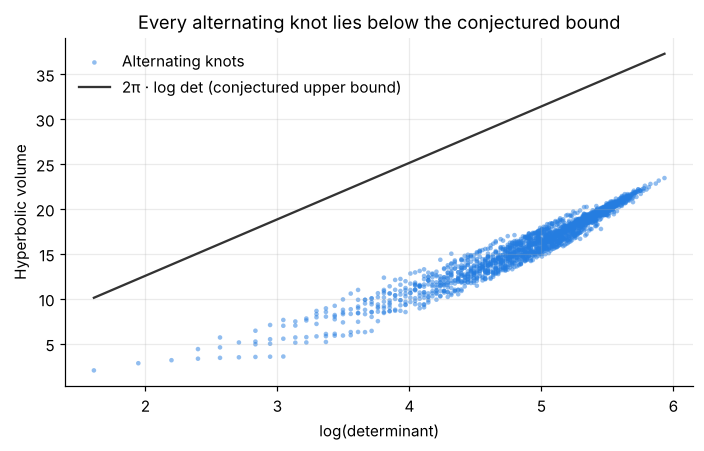

In [5]:
ha = ha.assign(bound=2 * np.pi * ha.log_det)
ha = ha.assign(ratio=ha.volume / ha.bound)
holds = (ha.volume < ha.bound).sum()
print(f"vol < 2*pi*log(det) holds for {holds} of {len(ha)} alternating hyperbolic knots")
print(f"Largest ratio vol / (2*pi*log det): {ha.ratio.max():.3f}")
print("Knots closest to the bound:")
print(ha.nlargest(5, "ratio")[["name", "crossing_number", "determinant", "volume", "bound", "ratio"]]
      .round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(ha.log_det, ha.volume, s=9, alpha=0.5, color=ALT, edgecolor="none", label="Alternating knots")
x = np.linspace(ha.log_det.min(), ha.log_det.max(), 100)
ax.plot(x, 2 * np.pi * x, color="#333", lw=1.5, label="2π · log det (conjectured upper bound)")
ax.set(xlabel="log(determinant)", ylabel="Hyperbolic volume",
       title="Every alternating knot lies below the conjectured bound")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig("figures/p1_ckp_bound.png", dpi=150); plt.show()

## Findings

1. **det(K) = |V(−1)| for all 2,977 knots**, confirming the data and code are consistent.
2. **The Kauffman–Murasugi–Thistlethwaite theorem shows up exactly:** span V equals the crossing number for every
   alternating knot and is strictly smaller for every non-alternating knot.
3. **The Jones polynomial carries geometric information.** Its value at t = −1 (the determinant) predicts
   hyperbolic volume far better than crossing number does (see the printed correlations).
4. **The Champanerkar–Kofman–Purcell bound vol < 2π log det holds for every alternating hyperbolic knot up to 12 crossings.**

**Next question (Project 2).** If one value of the Jones polynomial already predicts volume this well, can a neural
network learn volume from *all* of its coefficients, including for non-alternating knots?

**References.** L. H. Kauffman, *State models and the Jones polynomial*, Topology 26 (1987);
K. Murasugi, *Jones polynomials and classical conjectures in knot theory*, Topology 26 (1987);
A. Champanerkar, I. Kofman, J. Purcell, *Geometrically and diagrammatically maximal knots*, J. London Math. Soc. (2016);
C. Livingston and A. H. Moore, *KnotInfo: Table of Knot Invariants*.